In [1]:
library(tidyverse)
library(tidymodels)
library(glmnet)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──



✔ broom        1.0.11     ✔ rsample      1.3.1 
✔ dials        1.4.2      ✔ tailor       0.1.0 
✔ infer        1.0.9      ✔ tune         2.0.1 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.4.0      ✔ workflowsets 1.1.1 
✔ recipes      1.3.1      ✔ yardstick    1.3.2 



── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ scales::discard() masks purrr::discard()
✖ dplyr::filter()   masks stats::filter()
✖ recipes::fixed()  masks stringr::fixed()
✖ dplyr::lag()      masks stats::lag()
✖ yardstick::spec() masks readr::spec()
✖ recipes::step()   masks stats::step()



Loading required package: Matrix




Attaching package: ‘Matrix’




The following objects are masked from ‘package:tidyr’:

    expand, pack, unpack




Loaded glmnet 4.1-10



In [2]:
# Load CSV file
df <- read_csv("../../data/social_media_ad_optimization_raw.csv")

# Show basic info
cat("Rows:", nrow(df), "  Columns:", ncol(df), "\n")
head(df)

Rows: 500 Columns: 16


── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (10): user_id, gender, location, interests, ad_id, ad_category, ad_platf...
dbl  (6): age, impressions, clicks, conversion, time_spent_on_ad, engagement...



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Rows: 500   Columns: 16 


user_id,age,gender,location,interests,ad_id,ad_category,ad_platform,ad_type,impressions,clicks,conversion,time_spent_on_ad,day_of_week,device_type,engagement_score
<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>
U0001,58,M,USA,Food,A0001,Sportswear,Facebook,Image,3,0,0,3.38,Friday,Mobile,0.02
U0002,55,F,USA,Tech,A0002,Electronics,Facebook,Image,9,9,1,6.77,Saturday,Tablet,0.93
U0003,52,F,UK,Gaming,A0003,Luggage,Instagram,Image,13,12,1,13.26,Wednesday,Mobile,0.93
U0004,31,F,USA,Tech,A0004,Gadgets,Facebook,Video,14,5,0,24.41,Saturday,Desktop,0.28
U0005,52,M,India,Tech,A0005,Luggage,Instagram,Carousel,10,5,0,21.43,Monday,Tablet,0.35
U0006,32,F,USA,Fashion,A0006,Electronics,Instagram,Video,8,5,1,11.30,Saturday,Desktop,0.77


In [3]:
# Equivalent to df["time_spent_on_ad"].describe()
summary(df$time_spent_on_ad)


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.46    4.99   13.29   14.07   21.73   29.95 

In [4]:
# Safely drop column if it exists
df <- df %>% select(-any_of("engagement_score"))


In [5]:
# Convert target to categorical (factor)
df$conversion <- as.factor(df$conversion)

In [6]:
numeric_features <- c("age", "impressions", "clicks", "time_spent_on_ad")

categorical_features <- c(
  "gender", "location", "interests",
  "ad_category", "ad_platform", "ad_type",
  "day_of_week", "device_type"
)


In [7]:
# 🧩 Preprocessing — scale numeric + one-hot encode categoricals
preprocessor <- recipe(conversion ~ ., data = df) %>%
  # Drop non-predictive ID columns
  step_rm(user_id, ad_id) %>%
  # Normalize numeric features
  step_normalize(all_of(numeric_features)) %>%
  # One-hot encode categorical features
  step_dummy(all_of(categorical_features), one_hot = TRUE)




In [8]:
log_reg_model <- logistic_reg(mode = "classification", penalty = 0.01, mixture = 1) %>%
  set_engine("glmnet")

clf_lr <- workflow() %>%
  add_model(log_reg_model) %>%
  add_recipe(preprocessor)


In [9]:
# Split the data into training (80%) and testing (20%)
set.seed(42)
data_split <- initial_split(df, prop = 0.8, strata = conversion)
train_data <- training(data_split)
test_data  <- testing(data_split)



In [10]:
clf_lr_fit <- clf_lr %>% fit(data = train_data)


In [11]:
preds <- predict(clf_lr_fit, test_data, type = "class")
head(preds)

.pred_class
<fct>
0
0
1
0
0
1


In [12]:
results <- bind_cols(test_data, preds)

results <- results %>%
  mutate(
    conversion = factor(conversion, levels = levels(train_data$conversion)),
    .pred_class = factor(.pred_class, levels = levels(train_data$conversion))
  )

# Metrics
acc <- accuracy(results, truth = conversion, estimate = .pred_class)
prec <- precision(results, truth = conversion, estimate = .pred_class, event_level = "second")
rec <- recall(results, truth = conversion, estimate = .pred_class, event_level = "second")
f1 <- f_meas(results, truth = conversion, estimate = .pred_class, event_level = "second")

report <- bind_rows(acc, prec, rec, f1)
print(report)

# A tibble: 4 × 3
  .metric   .estimator .estimate
  <chr>     <chr>          <dbl>
1 accuracy  binary         0.57 
2 precision binary         0.55 
3 recall    binary         0.468
4 f_meas    binary         0.506


In [13]:
# quick sanity check
table(results$conversion)
table(results$.pred_class)


 0  1 
53 47 


 0  1 
60 40 

In [14]:
#confusion matrix
conf_mat(results, truth = conversion, estimate = .pred_class)

          Truth
Prediction  0  1
         0 35 25
         1 18 22

In [15]:
#predicted probabilities
probs <- predict(clf_lr_fit, test_data, type = "prob")
results_prob <- bind_cols(test_data, probs)
roc_auc(results_prob, truth = conversion, .pred_1, event_level = "second")

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
roc_auc,binary,0.637495


# A tibble: 20 × 3
   term                        estimate penalty
   <chr>                          <dbl>   <dbl>
 1 location_UK                  -0.404     0.01
 2 time_spent_on_ad              0.336     0.01
 3 day_of_week_Monday           -0.307     0.01
 4 interests_Tech               -0.291     0.01
 5 ad_type_Video                -0.288     0.01
 6 interests_Fitness            -0.286     0.01
 7 ad_category_Luggage          -0.264     0.01
 8 location_USA                 -0.254     0.01
 9 device_type_Tablet           -0.220     0.01
10 clicks                        0.206     0.01
11 gender_Other                  0.173     0.01
12 location_Canada               0.154     0.01
13 day_of_week_Wednesday         0.136     0.01
14 interests_Gaming              0.112     0.01
15 location_Australia            0.0836    0.01
16 age                          -0.0531    0.01
17 gender_M                     -0.0530    0.01
18 impressions                  -0.0402    0.01
19 device_type_Deskto

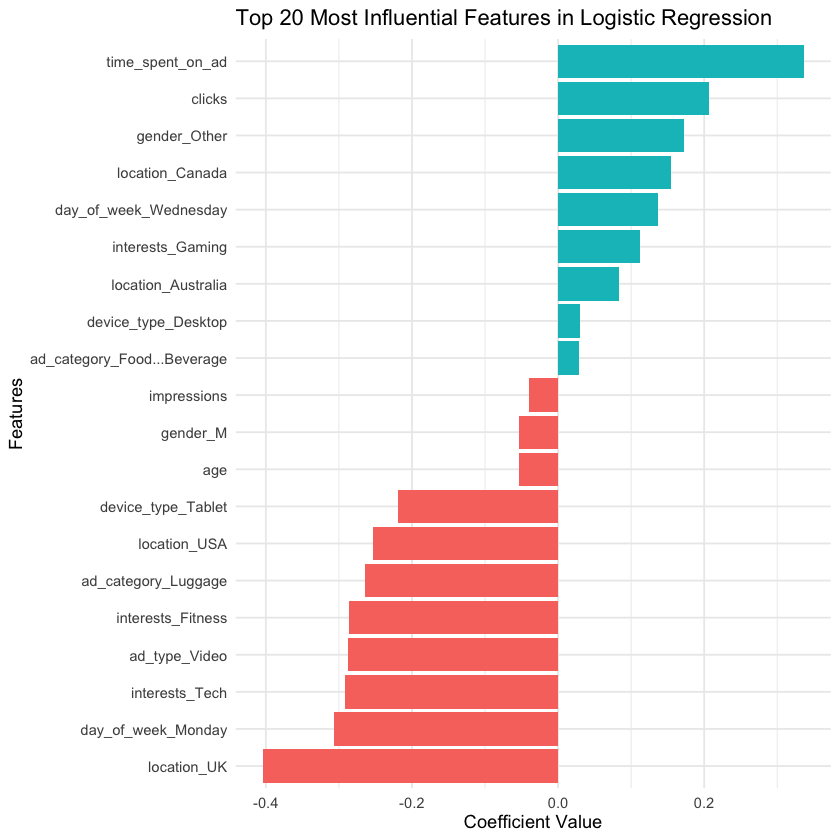

In [16]:
# 1️⃣ Extract model coefficients of the fitted glmnet model (at penalty = 0.01)
model_coef <- tidy(clf_lr_fit$fit$fit)

# 2️⃣ Top 20 features by absolute effect size (positive and negative)
top_features <- model_coef %>%
  filter(term != "(Intercept)") %>%
  slice_max(order_by = abs(estimate), n = 20)

print(top_features)

# 3️⃣ Visualize feature importance
ggplot(top_features, aes(x = reorder(term, estimate), y = estimate, fill = estimate > 0)) +
  geom_bar(stat = "identity", show.legend = FALSE) +
  coord_flip() +
  labs(title = "Top 20 Most Influential Features in Logistic Regression",
       x = "Features",
       y = "Coefficient Value") +
  theme_minimal()

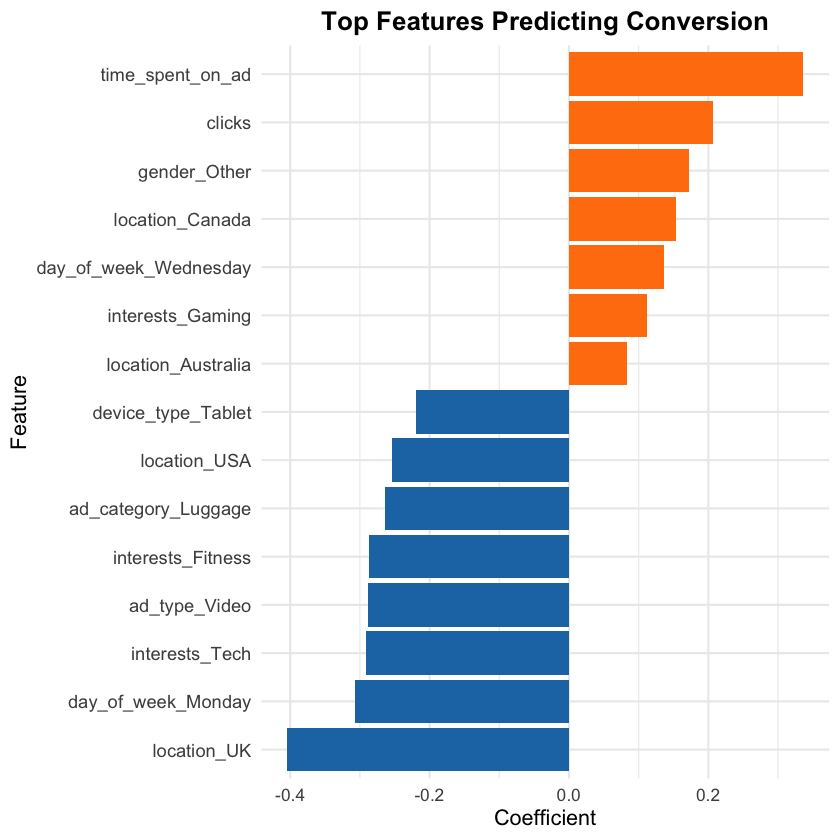

In [17]:
library(ggplot2)
library(dplyr)

# Assuming you already have your coefficients in 'model_coef' or 'top_features'
# If not, rebuild feature importance dataframe
feat_imp <- tidy(clf_lr_fit$fit$fit) %>%
  filter(term != "(Intercept)") %>%
  arrange(desc(estimate))

# Pick top 15
top15 <- feat_imp %>%
  slice_max(order_by = abs(estimate), n = 15)

# Plot
ggplot(top15, aes(x = estimate, y = reorder(term, estimate), fill = estimate > 0)) +
  geom_col(show.legend = FALSE) +
  labs(
    title = "Top Features Predicting Conversion",
    x = "Coefficient",
    y = "Feature"
  ) +
  scale_fill_manual(values = c("#1f77b4", "#ff7f0e")) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    axis.text.y = element_text(size = 11)
  )